In [2]:
from getpass import getuser # Libaray to copy things
from pathlib import Path # Object oriented libary to deal with paths
from dask.utils import format_bytes
from distributed import Client, progress, wait # Libaray to orchestrate distributed resources
#from dask_jobqueue import SLURMCluster # Setting up distributed memories via slurm
import numpy as np # Pythons standard array library
import xarray as xr # Libary to work with labeled n-dimensional data
import dask # Distributed data libary
import dask.distributed
import multiprocessing
from dask.diagnostics import ProgressBar
import glob, os
from matplotlib.patches import Patch
from scipy.ndimage import gaussian_filter1d
from scipy import stats
from subprocess import run, PIPE
import sys
import gc
from concurrent.futures import ProcessPoolExecutor
import seaborn as sns
import warnings
warnings.filterwarnings(action='ignore')
dask.config.config.get('distributed').get('dashboard').update({'link':'{JUPYTERHUB_SERVICE_PREFIX}/proxy/{port}/status'})
import pandas as pd
from scipy.interpolate import CloughTocher2DInterpolator, LinearNDInterpolator, NearestNDInterpolator

In [3]:
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from matplotlib import pyplot as plt # Standard Plotting library
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from cartopy import crs as ccrs # Cartography library
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import cartopy.feature as cfeature
import matplotlib.ticker as mticker
import matplotlib.tri as tri

In [4]:
#'''Provides information about the CPU and starts the dask client'''
ncpu = multiprocessing.cpu_count()
processes = False
nworker = 1
threads = ncpu // nworker
print(f"Number of CPUs: {ncpu}, number of threads: {threads}, number of workers: {nworker}, processes: {processes}")
client = Client(processes=processes,
 threads_per_worker=threads,
 n_workers=nworker,
 memory_limit='1000GB'
 )

Number of CPUs: 64, number of threads: 64, number of workers: 1, processes: False


In [15]:
test = xr.open_dataset('/home/jwille/xenon_data/IGE_data/ERA5/OUT2.nc')

test2 = xr.open_dataset('/net/thermo/atmosdyn/michaesp/contact.jonathan.wille/S20000101_00')





In [16]:
print(test.lon)

<xarray.DataArray 'lon' (lon: 720)> Size: 3kB
array([-180. , -179.5, -179. , ...,  178.5,  179. ,  179.5], dtype=float32)
Coordinates:
  * lon      (lon) float32 3kB -180.0 -179.5 -179.0 -178.5 ... 178.5 179.0 179.5
Attributes:
    long_name:  longitude
    units:      degrees_east


In [17]:
print(test2.lon)

<xarray.DataArray 'lon' (lon: 720)> Size: 3kB
array([-180. , -179.5, -179. , ...,  178.5,  179. ,  179.5], dtype=float32)
Coordinates:
  * lon      (lon) float32 3kB -180.0 -179.5 -179.0 -178.5 ... 178.5 179.0 179.5
Attributes:
    standard_name:  longitude
    long_name:      longitude
    units:          degrees_east
    axis:           X


In [5]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.patches import Patch
from pathlib import Path

# ── 1. Load data ──────────────────────────────────────────────────────────────
ifs = xr.open_dataset(
    '/home/jwille/xenon_data/NextGEMS/dry_spells/'
    'IFS_cycle4_summer_1990-2049_dry_spell_annual_30-60N.nc'
)['__xarray_dataarray_variable__']

# Land-sea mask (shared value dimension with ifs)
land_sea_ifs_zoom9 = xr.open_dataset(
    '/home/jwille/xenon_data/NextGEMS/NextGEMS/IFS_zoom9/30-60N_ifs_hpx512_lsm.nc'
)['lsm']

# Apply land mask and slice to 2020–2049 (indices 30–60)
ifs_land = ifs.where(land_sea_ifs_zoom9 > 0, np.nan)#[31:60, :]

# ── 2. Split into first 15 and last 15 years ──────────────────────────────────


early = ifs_land.isel(year=slice(31,45))
late = ifs_land.isel(year=slice(45,60))

# ── 3. Define dry-spell bins and compute area fractions ───────────────────────
bin_edges  = [0, 10, 20, 30, 50, np.inf]
bin_labels = ['0–10', '10–20', '20–30', '30–50', '50+']

def area_fractions(da):
    """
    For a DataArray with dims (year, value), compute the mean area fraction (%)
    in each dry-spell bin, averaged across years.
    Land points only (NaNs already applied via land-sea mask).
    """
    fracs_per_year = []
    for yr in da.year.values:
        vals = da.sel(year=yr).values.ravel()
        vals = vals[~np.isnan(vals)]
        total = vals.size
        if total == 0:
            fracs_per_year.append([np.nan] * len(bin_labels))
            continue
        fracs = []
        for lo, hi in zip(bin_edges[:-1], bin_edges[1:]):
            mask = (vals >= lo) & (vals < hi)
            fracs.append(100.0 * mask.sum() / total)
        fracs_per_year.append(fracs)
    return np.array(fracs_per_year)   # shape: (n_years, n_bins)

early_fracs = area_fractions(early)   # (15, 5)
late_fracs  = area_fractions(late)    # (15, 5)

early_mean = np.nanmean(early_fracs, axis=0)
late_mean  = np.nanmean(late_fracs,  axis=0)

#pct_change = 100.0 * (late_mean - early_mean) / early_mean   # relative % change
pct_change = late_mean - early_mean


In [6]:
print(early)

<xarray.DataArray '__xarray_dataarray_variable__' (year: 14, value: 574808)> Size: 64MB
array([[174., 184., 184., ...,  11.,  11.,  11.],
       [112., 112., 112., ...,  11.,  11.,  15.],
       [184., 184., 168., ...,  17.,  17.,  17.],
       ...,
       [184., 184., 170., ...,  21.,  21.,  21.],
       [ 95., 184., 184., ...,   9.,  10.,  14.],
       [173., 173., 173., ...,  40.,  20.,  20.]])
Coordinates:
    lat      (value) float64 5MB 30.09 30.09 30.09 30.17 ... 41.61 41.61 41.71
    lon      (value) float64 5MB 56.07 55.72 55.9 55.99 ... 270.1 269.9 270.0
  * value    (value) int64 5MB 0 1 2 3 4 ... 574803 574804 574805 574806 574807
Dimensions without coordinates: year
Attributes:
    cell_methods:  year: mean


In [7]:
print(late)

<xarray.DataArray '__xarray_dataarray_variable__' (year: 15, value: 574808)> Size: 69MB
array([[105., 105., 105., ...,  17.,  17.,  17.],
       [138., 144., 144., ...,  21.,  21.,  21.],
       [177., 180., 180., ...,  19.,  19.,  14.],
       ...,
       [ 98., 115., 115., ...,  14.,  12.,  12.],
       [184., 183., 183., ...,  45.,  45.,  39.],
       [184., 184., 184., ...,  25.,  24.,  15.]])
Coordinates:
    lat      (value) float64 5MB 30.09 30.09 30.09 30.17 ... 41.61 41.61 41.71
    lon      (value) float64 5MB 56.07 55.72 55.9 55.99 ... 270.1 269.9 270.0
  * value    (value) int64 5MB 0 1 2 3 4 ... 574803 574804 574805 574806 574807
Dimensions without coordinates: year
Attributes:
    cell_methods:  year: mean


In [8]:
print

<function print(*args, sep=' ', end='\n', file=None, flush=False)>

In [9]:
print(pct_change)


[-2.3572533  -2.45811505  1.19123537  1.15359301  2.47053997]


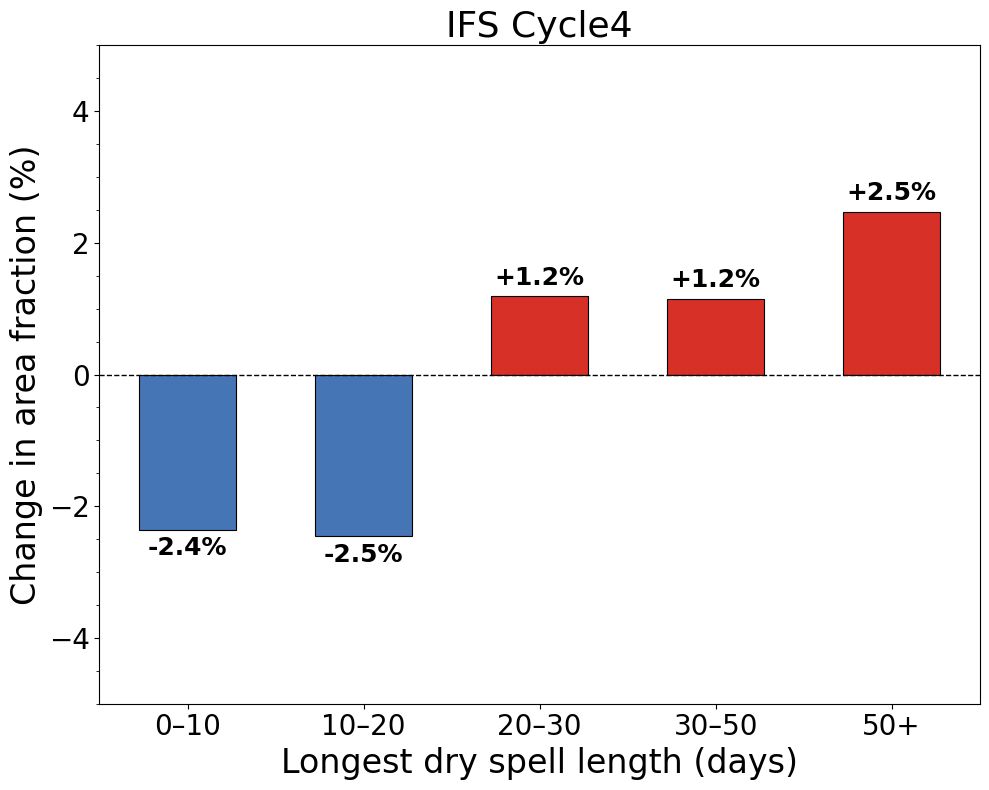

In [10]:
# ── 4. Plot ───────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 8))

x      = np.arange(len(bin_labels))
width  = 0.55
colors = ['#d73027' if v >= 0 else '#4575b4' for v in pct_change]

bars = ax.bar(x, pct_change, width=width, color=colors, edgecolor='k', linewidth=0.8)

# Annotate bars with numeric values
for bar, val in zip(bars, pct_change):
    yoffset = 0.1 if val >= 0 else -0.1
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + yoffset,
        f'{val:+.1f}%',
        ha='center',
        va='bottom' if val >= 0 else 'top',
        fontsize=18, fontweight='bold'
    )

ax.axhline(0, color='black', linewidth=1.0, linestyle='--')

ax.set_xticks(x)
ax.set_xticklabels(bin_labels, fontsize=20)
ax.set_xlabel('Longest dry spell length (days)', fontsize=24)
ax.set_ylabel('Change in area fraction (%)', fontsize=24)
ax.tick_params(axis='both', labelsize=20)
ax.yaxis.set_minor_locator(mticker.AutoMinorLocator())
ax.set_ylim(-5, 5)


ax.set_title('IFS Cycle4',fontsize=26)

legend_elements = [
    Patch(facecolor='#d73027', edgecolor='k', label='Increase'),
    Patch(facecolor='#4575b4', edgecolor='k', label='Decrease'),
]
#ax.legend(handles=legend_elements, fontsize=14, loc='upper right')

plt.tight_layout()
plt.savefig(
    '/home/jwille/images/global_paper/mid_lat_land_IFS_cycle4_barplot_dry_spell_change.pdf',
    format='pdf', bbox_inches='tight')
plt.show()